In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path

sns.set_theme(style="whitegrid")
OUT = Path("figures")
OUT.mkdir(exist_ok=True)

COLOURS = {"Developed": "#1f77b4", "Developing": "#d95f02"}
ISO3 = {"Switzerland": "CHE", "United States": "USA", "Germany": "DEU",
        "South Africa": "ZAF", "China": "CHN", "India": "IND"}

pub = pd.read_csv("clean-pt2/publications_summary_6countries.csv")
pub["iso3"] = pub["country"].map(ISO3)
pub["cites_per_article"] = pub["num_citations"] / pub["num_articles"]

pub_totals = pub[pub["field"] == "All"].copy()
pub_topics = pub[pub["field"] != "All"].copy()

# Each topic as a share of its country's total articles
pub_topics = pub_topics.merge(
    pub_totals[["country", "num_articles"]].rename(columns={"num_articles": "total_articles"}),
    on="country")
pub_topics["share_pct"] = pub_topics["num_articles"] / pub_topics["total_articles"] * 100

print(pub_totals[["country", "num_articles", "num_citations", "cites_per_article"]].round(1))
print(pub_topics["field"].unique())

          country  num_articles  num_citations  cites_per_article
6    South Africa          6681         147419               22.1
7   United States        376956       15302556               40.6
8     Switzerland         25091        1119172               44.6
9           India        252531        2854407               11.3
10          China        644908       14523421               22.5
11        Germany         95756        2802123               29.3
<StringArray>
[                  'AI Safety',             'Computer Vision',
       'Large language models', 'Natural Language Processing',
                    'Robotics']
Length: 5, dtype: str


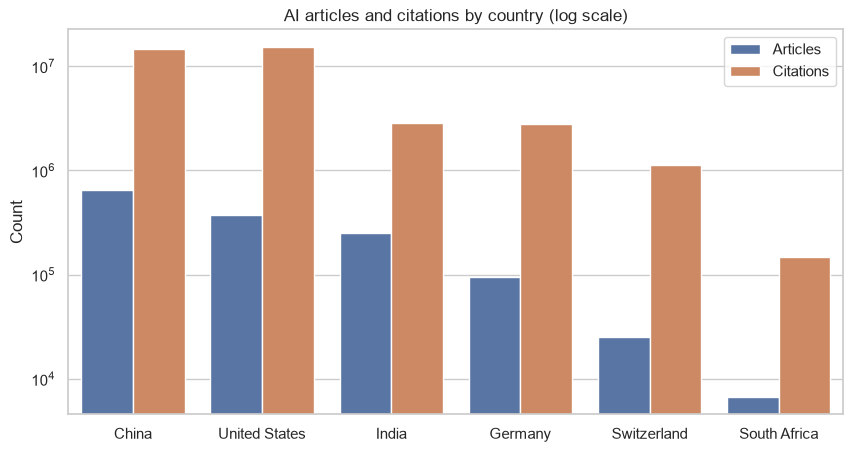

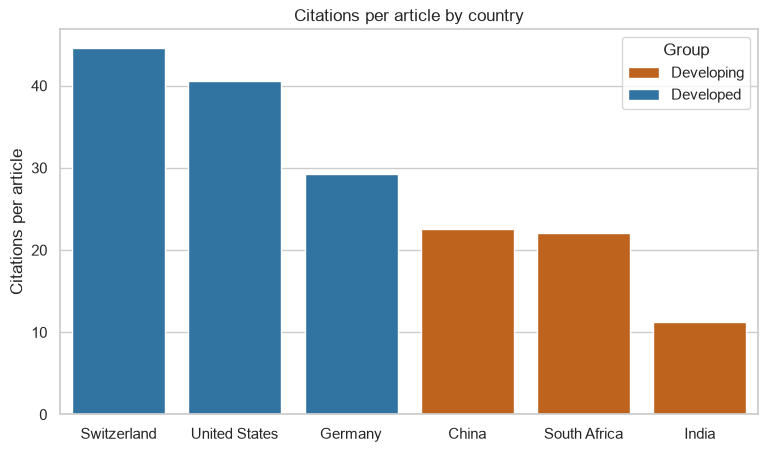

            num_articles  num_citations  cites_per_article
group                                                     
Developed         497803       19223851               38.6
Developing        904120       17525247               19.4


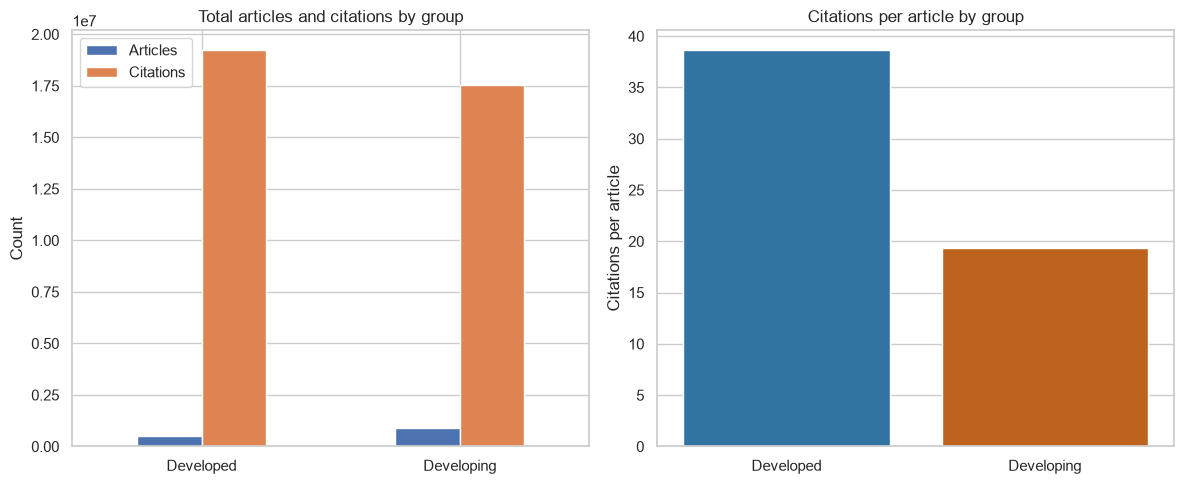

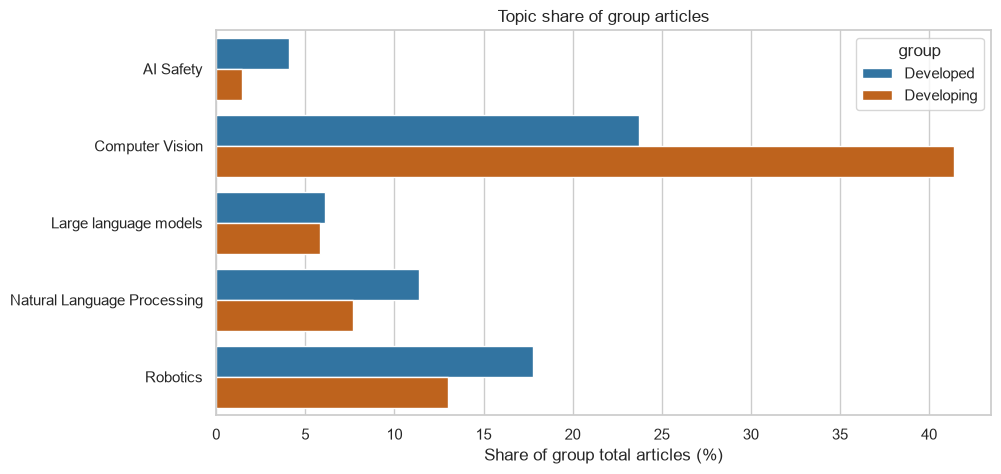

In [3]:
# 1. Articles and citations by country (log scale because volumes differ widely)
order = pub_totals.sort_values("num_articles", ascending=False)["country"]
long = pub_totals.melt(id_vars=["country", "group"], value_vars=["num_articles", "num_citations"], var_name="type", value_name="count")
long["type"] = long["type"].map({"num_articles": "Articles", "num_citations": "Citations"})

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=long, x="country", y="count", hue="type", order=order, ax=ax)
ax.set_yscale("log")
ax.set_title("AI articles and citations by country (log scale)")
ax.set_xlabel("")
ax.set_ylabel("Count")
ax.legend(title="")
fig.savefig(OUT / "pubs_totals_by_country.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Citations per article by country
order_cpa = pub_totals.sort_values("cites_per_article", ascending=False)["country"]
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=pub_totals, x="country", y="cites_per_article", hue="group", palette=COLOURS, order=order_cpa, dodge=False, ax=ax)
ax.set_title("Citations per article by country")
ax.set_xlabel("")
ax.set_ylabel("Citations per article")
ax.legend(title="Group")
fig.savefig(OUT / "pubs_cites_per_article.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Developed vs developing (rates use summed counts, not averages of rates)
grp = pub_totals.groupby("group")[["num_articles", "num_citations"]].sum()
grp["cites_per_article"] = grp["num_citations"] / grp["num_articles"]
print(grp.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
grp[["num_articles", "num_citations"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Total articles and citations by group")
axes[0].set_xlabel("")
axes[0].set_ylabel("Count")
axes[0].legend(["Articles", "Citations"])

sns.barplot(x=grp.index, y=grp["cites_per_article"], hue=grp.index, palette=COLOURS, legend=False, ax=axes[1])
axes[1].set_title("Citations per article by group")
axes[1].set_xlabel("")
axes[1].set_ylabel("Citations per article")
fig.tight_layout()
fig.savefig(OUT / "pubs_group_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# 4. Topic mix: each topic as a share of the group's total articles
tg = pub_topics.groupby(["group", "field"])[["num_articles", "total_articles"]].sum().reset_index()
tg["share_pct"] = tg["num_articles"] / tg.groupby("group")["total_articles"].transform("first") * 100
tot_group = pub_totals.groupby("group")["num_articles"].sum()
tg["share_pct"] = tg["num_articles"] / tg["group"].map(tot_group) * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=tg, y="field", x="share_pct", hue="group", palette=COLOURS, ax=ax)
ax.set_title("Topic share of group articles")
ax.set_xlabel("Share of group total articles (%)")
ax.set_ylabel("")
fig.savefig(OUT / "pubs_topic_share.png", dpi=300, bbox_inches="tight")
plt.show()


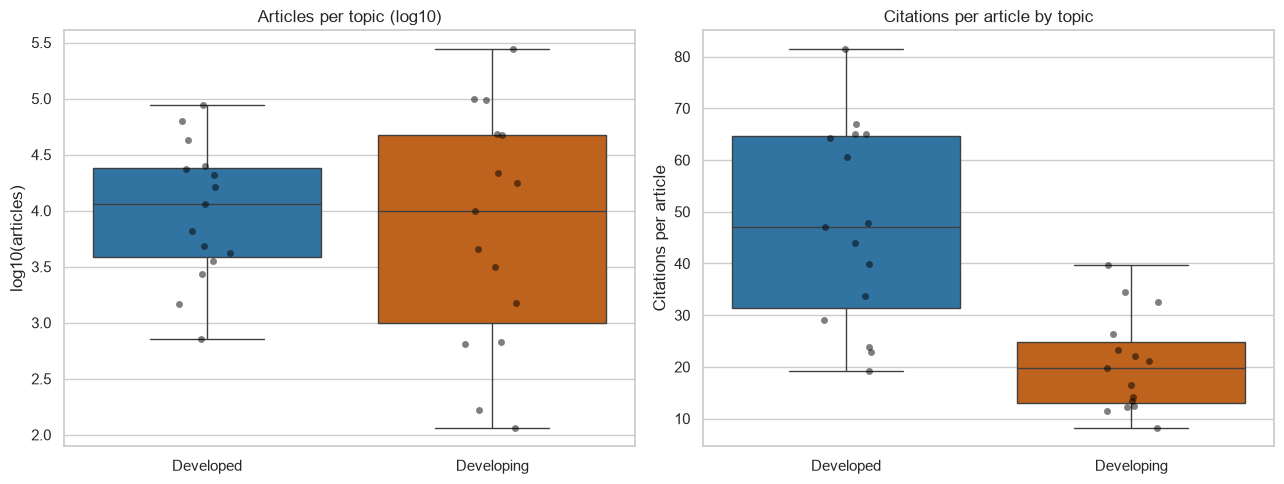

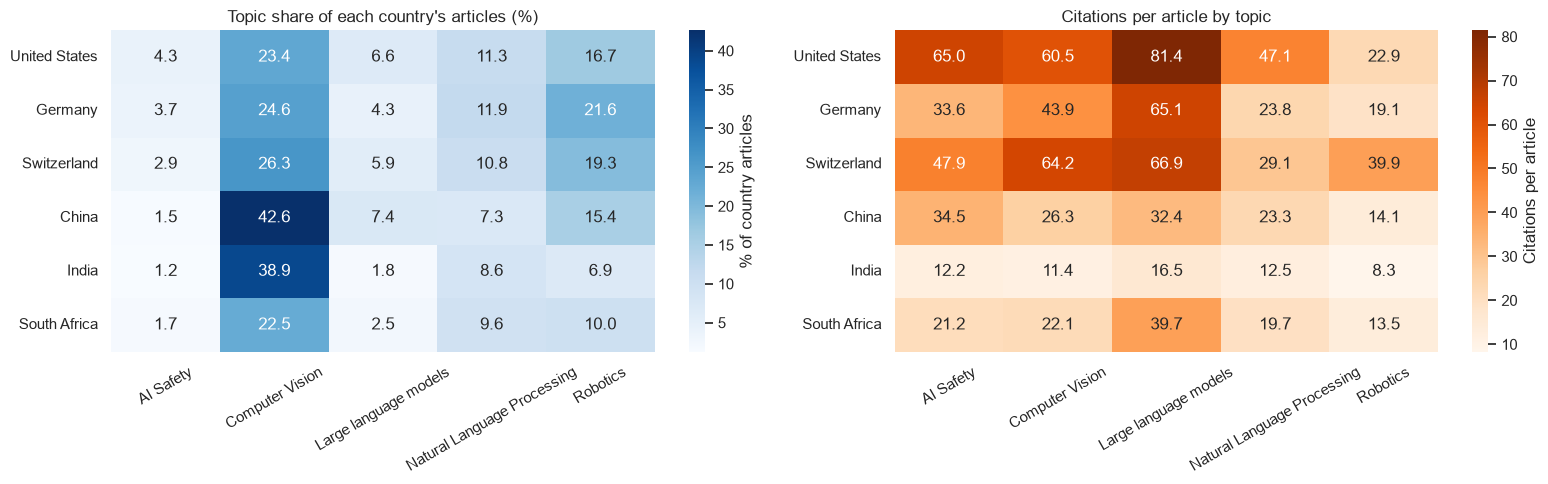

In [4]:
order = ["United States", "Germany", "Switzerland", "China", "India", "South Africa"]
pub_topics["log_articles"] = np.log10(pub_topics["num_articles"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=pub_topics, x="group", y="log_articles", hue="group", palette=COLOURS, legend=False, ax=axes[0])
sns.stripplot(data=pub_topics, x="group", y="log_articles", color="black", alpha=0.5, size=5, ax=axes[0])
axes[0].set_title("Articles per topic (log10)")
axes[0].set_xlabel("")
axes[0].set_ylabel("log10(articles)")

sns.boxplot(data=pub_topics, x="group", y="cites_per_article", hue="group", palette=COLOURS, legend=False, ax=axes[1])
sns.stripplot(data=pub_topics, x="group", y="cites_per_article", color="black", alpha=0.5, size=5, ax=axes[1])
axes[1].set_title("Citations per article by topic")
axes[1].set_xlabel("")
axes[1].set_ylabel("Citations per article")

fig.tight_layout()
fig.savefig(OUT / "pubs_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# Heatmaps: topic share of each country's articles, and citations per article
share = pub_topics.pivot(index="country", columns="field", values="share_pct").loc[order]
cpa = pub_topics.pivot(index="country", columns="field", values="cites_per_article").loc[order]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(share, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of country articles"}, ax=axes[0])
axes[0].set_title("Topic share of each country's articles (%)")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

sns.heatmap(cpa, annot=True, fmt=".1f", cmap="Oranges", cbar_kws={"label": "Citations per article"}, ax=axes[1])
axes[1].set_title("Citations per article by topic")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

for ax in axes:
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(OUT / "pubs_topic_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
pub_totals["log_articles"] = np.log10(pub_totals["num_articles"])

# Map 1: article volume (log scale colour, real counts in the hover text)
fig = px.choropleth(pub_totals, locations="iso3", color="log_articles",
                    hover_name="country",
                    hover_data={"iso3": False, "log_articles": False,
                                "num_articles": ":,", "num_citations": ":,"},
                    color_continuous_scale="Viridis",
                    labels={"log_articles": "log10(articles)"},
                    title="AI research articles by country (log10 scale)")
fig.update_geos(showcountries=True, projection_type="natural earth")
fig.update_layout(margin=dict(l=0, r=0, t=50, b=0))
fig.write_html(OUT / "pubs_articles_map.html")
fig.show()

# Map 2: citations per article
fig = px.choropleth(pub_totals, locations="iso3", color="cites_per_article",
                    hover_name="country",
                    hover_data={"iso3": False, "cites_per_article": ":.1f"},
                    color_continuous_scale="Viridis",
                    labels={"cites_per_article": "Citations per article"},
                    title="Citations per article by country")
fig.update_geos(showcountries=True, projection_type="natural earth")
fig.update_layout(margin=dict(l=0, r=0, t=50, b=0))
fig.write_html(OUT / "pubs_cites_per_article_map.html")
fig.show()

In [6]:
YEARS = list(range(2018, 2025))

art = pd.read_csv("clean-pt2/publications_yearly_articles_6countries.csv")
cit = pd.read_csv("clean-pt2/publications_yearly_citations_6countries.csv")

art = art[art["year"].between(2018, 2024)].copy()
cit = cit[cit["year"].between(2018, 2024)].copy()

art_all = art[art["field"] == "All"]
cit_all = cit[cit["field"] == "All"]

print("Articles, All rows (* = flagged incomplete)")
tbl = art_all.assign(v=art_all["num_articles"].astype(str) + np.where(art_all["complete"], "", "*"))
print(tbl.pivot(index="country", columns="year", values="v").fillna("missing"))

print("\nCitations, All rows")
print(cit_all.pivot(index="country", columns="year", values="num_citations").reindex(columns=YEARS))

print("\nShare of article rows flagged incomplete, by year")
print(art.groupby("year")["complete"].apply(lambda s: (~s).mean()).round(2))

print("\nTopics in the yearly files:", sorted(art["field"].unique()))

Articles, All rows (* = flagged incomplete)
year            2018   2019   2020   2021   2022    2023    2024
country                                                         
China          36754  48935  56769  72439  82800  104292  110110
Germany         7256   8550  10050  11870  12257   13936   12207
India          14100  16142  20777  29077  31239   43664   51154
South Africa     383    469    692    804    841    1113    1087
Switzerland     1829   2161   2561   3124   3534    3641    3153
United States  29526  36330  42988  46801  43440   50230   48876

Citations, All rows
year              2018     2019     2020     2021     2022     2023    2024
country                                                                    
China          1551273  2022008  2157692  2104518  1725881  1633678  913729
Germany         340082   370698   428839   371138   284101   254193  123615
India           256742   315417   421461   438782   390905   372532  242043
South Africa     10025    17744    

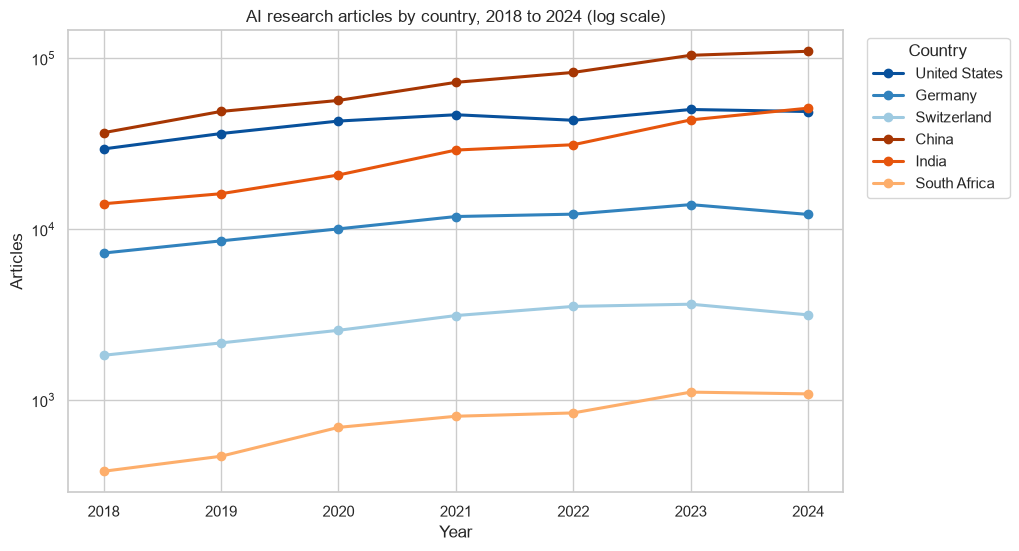

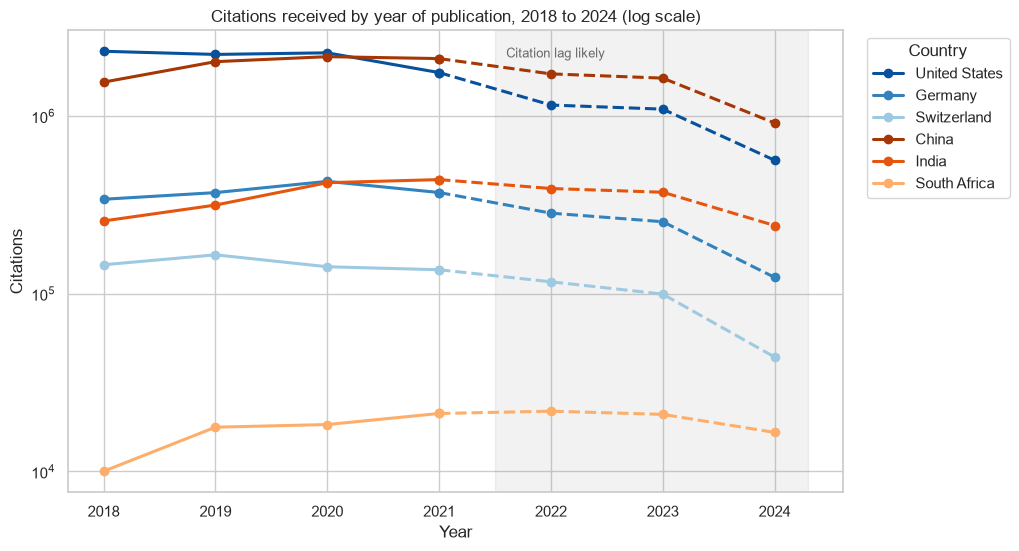

In [7]:
COUNTRY_COLOURS = {
    "United States": "#08519c", "Germany": "#3182bd", "Switzerland": "#9ecae1",
    "China": "#a63603", "India": "#e6550d", "South Africa": "#fdae6b",
}


def plot_trend(df, value_col, title, ylabel, fname, lag_from=None):
    wide = df.pivot(index="year", columns="country", values=value_col).reindex(YEARS)
    fig, ax = plt.subplots(figsize=(10, 6))

    for country, colour in COUNTRY_COLOURS.items():
        s = wide[country]
        if lag_from is None:
            ax.plot(s.index, s, color=colour, marker="o", linewidth=2.2, label=country)
        else:
            ax.plot(s.loc[:lag_from - 1].index, s.loc[:lag_from - 1], color=colour,
                    marker="o", linewidth=2.2, label=country)
            ax.plot(s.loc[lag_from - 1:].index, s.loc[lag_from - 1:], color=colour,
                    marker="o", linewidth=2.2, linestyle="--")

    if lag_from is not None:
        ax.axvspan(lag_from - 0.5, 2024.3, color="grey", alpha=0.10)
        ax.text(lag_from - 0.4, ax.get_ylim()[1], "Citation lag likely", va="top",
                fontsize=9, color="dimgrey")

    ax.set_yscale("log")
    ax.set_xticks(YEARS)
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.savefig(OUT / fname, dpi=300, bbox_inches="tight")
    plt.show()


plot_trend(art_all, "num_articles",
           "AI research articles by country, 2018 to 2024 (log scale)",
           "Articles", "pubs_trend_articles.png")

plot_trend(cit_all, "num_citations",
           "Citations received by year of publication, 2018 to 2024 (log scale)",
           "Citations", "pubs_trend_citations.png", lag_from=2022)

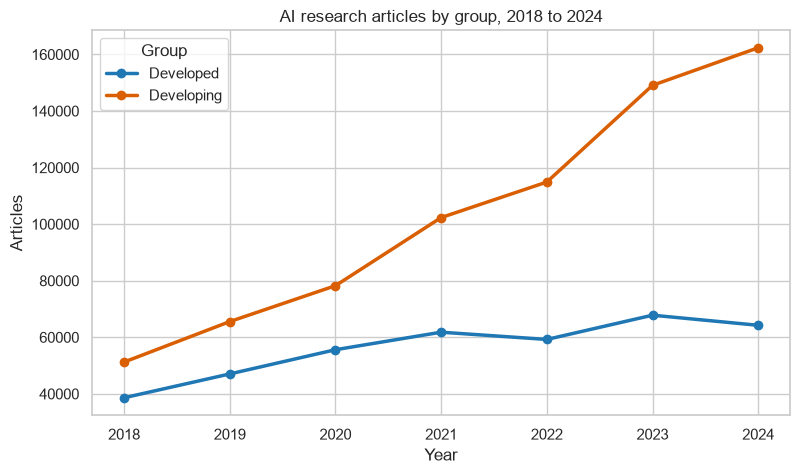

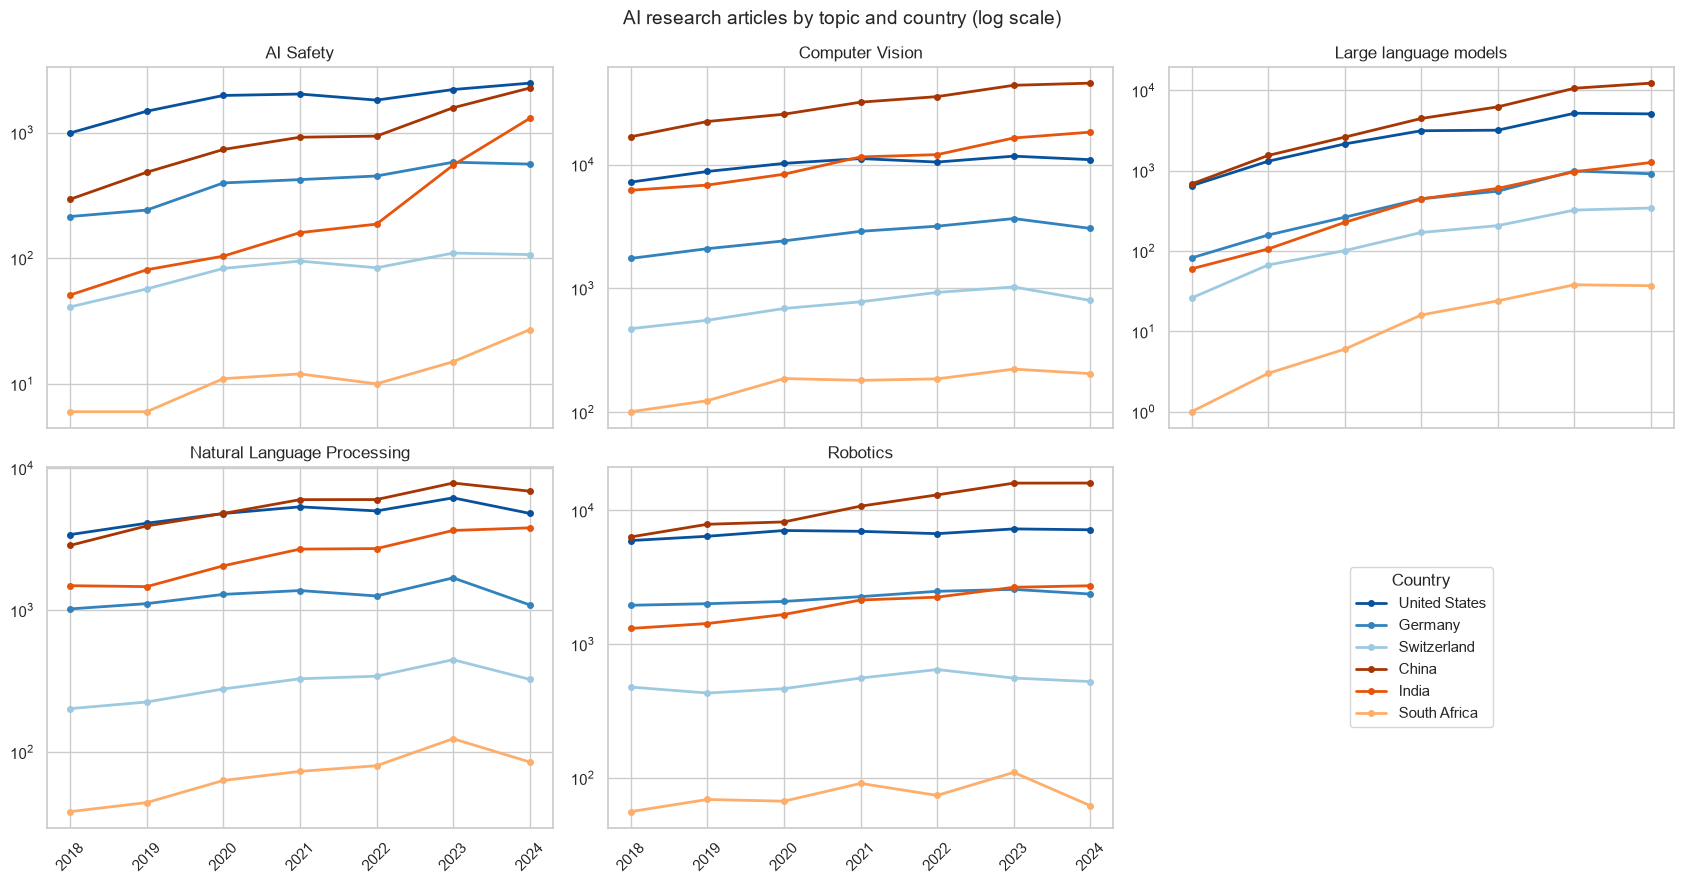

field
AI Safety                      42
Computer Vision                42
Large language models          42
Natural Language Processing    42
Robotics                       42
Name: num_articles, dtype: int64


In [8]:
# Part 1: group level article trend
grp_yr = art_all.groupby(["year", "group"])["num_articles"].sum().unstack().reindex(YEARS)

fig, ax = plt.subplots(figsize=(9, 5))
for g in ["Developed", "Developing"]:
    ax.plot(grp_yr.index, grp_yr[g], color=COLOURS[g], marker="o", linewidth=2.5, label=g)
ax.set_xticks(YEARS)
ax.set_title("AI research articles by group, 2018 to 2024")
ax.set_xlabel("Year")
ax.set_ylabel("Articles")
ax.legend(title="Group")
fig.savefig(OUT / "pubs_trend_group.png", dpi=300, bbox_inches="tight")
plt.show()

# Part 2: topic trends, one panel per topic
topics = ["AI Safety", "Computer Vision", "Large language models",
          "Natural Language Processing", "Robotics"]
topic_df = art[art["field"].isin(topics)]

fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True)
axes = axes.flatten()

for ax, topic in zip(axes, topics):
    d = topic_df[topic_df["field"] == topic]
    wide = d.pivot(index="year", columns="country", values="num_articles").reindex(YEARS)
    for country, colour in COUNTRY_COLOURS.items():
        if country in wide.columns:
            ax.plot(wide.index, wide[country], color=colour, marker="o",
                    linewidth=2, markersize=4, label=country)
    ax.set_yscale("log")
    ax.set_title(topic)
    ax.set_xticks(YEARS)
    ax.tick_params(axis="x", rotation=45)

# Use the spare sixth panel for the legend
handles, labels = axes[0].get_legend_handles_labels()
axes[5].axis("off")
axes[5].legend(handles, labels, title="Country", loc="center", fontsize=11)

fig.suptitle("AI research articles by topic and country (log scale)", fontsize=14)
fig.tight_layout()
fig.savefig(OUT / "pubs_topic_trends.png", dpi=300, bbox_inches="tight")
plt.show()

print(topic_df.groupby("field")["num_articles"].count())

In [9]:
f = next(Path("clean-pt2").glob("summary_st*"))
d = pd.read_csv(f)
print(f.name, "|", d.shape[0], "rows x", d.shape[1], "cols")
print(d.head(12).to_string())

summary_statistics.csv | 36 rows x 13 cols
               indicator        country  count       mean    median       std      min       max     range       Q1        Q3      IQR    CV
0   disclosed_investment          China      7    8990.00    9394.0   2651.51   5551.0   12486.0    6935.0   7146.5   10603.0   3456.5  0.29
1   disclosed_investment        Germany      7    2204.57    2415.0   1344.05    585.0    4007.0    3422.0   1058.5    3154.0   2095.5  0.61
2   disclosed_investment          India      7    4700.29    1902.0   7094.04    503.0   20513.0   20010.0   1249.5    3742.5   2493.0  1.51
3   disclosed_investment   South Africa      7      72.29      59.0     54.12      9.0     141.0     132.0     33.0     115.5     82.5  0.75
4   disclosed_investment    Switzerland      7     600.00     437.0    371.38    291.0    1302.0    1011.0    346.0     739.0    393.0  0.62
5   disclosed_investment  United States      7   69025.29   59585.0  36691.33  35690.0  128834.0   93144.0  400